# Etapa 3 — Distancias BFS hacia las salidas

**Objetivo:** comprobar que `Entorno.calcular_distancias()` calcula las distancias mínimas a las salidas y considera los obstáculos y el humo. Primero se examinan distancias conocidas y luego se bloquea una celda artificialmente para verificar que cambie su valor.

**Antes de ejecutar:** completar `Entorno.calcular_distancias()`.

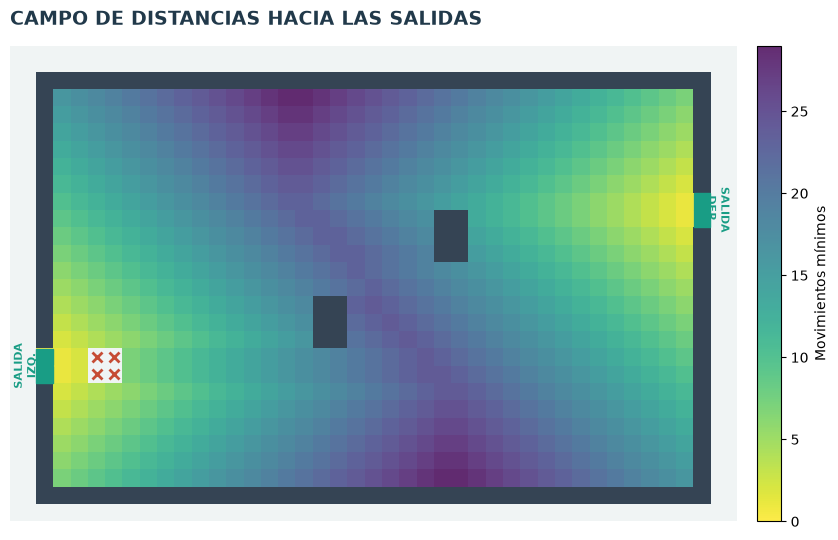

In [1]:
import matplotlib.pyplot as plt
from modelo import Configuracion, Entorno
from visualizacion import mostrar_distancias

# Calcular el campo inicial y representarlo gráficamente.
entorno = Entorno(Configuracion(usar_humo=True))
distancias = entorno.calcular_distancias()
figura = mostrar_distancias(entorno, distancias)
plt.show()

## Prueba 1. Distancias conocidas

Las salidas deben tener distancia **0**. Frente a la salida izquierda, las celdas `(1, 7)` y `(2, 7)` están a **1** y **2** movimientos. Las paredes y el foco de incendio deben tener distancia **-1**.

In [2]:
# Todas las celdas de salida son puntos de partida de BFS.
assert all(distancias[y, x] == 0 for x, y in entorno.salidas)

# Distancias conocidas de uno y dos pasos desde la salida izquierda.
assert distancias[7, 1] == 1
assert distancias[7, 2] == 2

# Pared exterior, obstáculo interior y foco: inaccesibles.
assert distancias[0, 0] == -1
assert distancias[10, 16] == -1
assert all(distancias[y, x] == -1 for x, y in entorno.fuentes)
print("Prueba 1: distancias correctas.")

Prueba 1: distancias correctas.


## Prueba 2. Recalcular ante un bloqueo por humo

Se asigna artificialmente una concentración de **0,55** a `(2, 7)`, superior al umbral (0,40). Tras recalcular BFS, esa celda debe pasar de distancia 2 a **-1**. La celda `(1, 7)` sigue junto a la salida y debe conservar distancia **1**.

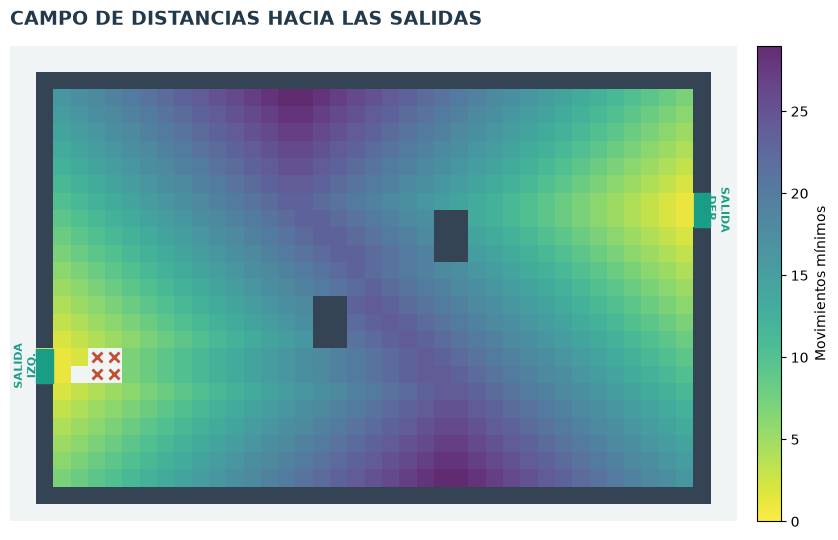

Prueba 2: bloqueo considerado correctamente.


In [3]:
# Forzar un bloqueo sin ejecutar la difusión del humo.
entorno.humo[7, 2] = 0.55

# El nuevo BFS debe considerar el cambio de transitabilidad.
nuevo_campo = entorno.calcular_distancias()
assert nuevo_campo[7, 2] == -1  # Ahora está bloqueada.
assert nuevo_campo[7, 1] == 1   # Sigue junto a la salida.

# Visualizar el efecto del bloqueo en el campo BFS.
figura = mostrar_distancias(entorno, nuevo_campo)
plt.show()
print("Prueba 2: bloqueo considerado correctamente.")

**Para discutir:** el BFS es una información global compartida, mientras que cada agente elige únicamente entre cuatro destinos vecinos. ¿Qué hipótesis sobre conocimiento del recinto estamos suponiendo?